<a href="https://colab.research.google.com/github/subhamswagatmohapatra-cmd/AML-LAB-/blob/main/AML_Experiment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

df = pd.read_excel("cgpaPRED.xls", engine="xlrd")
df.to_excel("cgpaPRED.xlsx", index=False)

In [3]:
import pandas as pd

df = pd.read_excel("/content/cgpaPRED.xlsx")

In [4]:
import pandas as pd
import numpy as np
print(df.head())
print(df.info())
print(df.isnull().sum())
df.drop_duplicates(inplace=True)
for col in df.select_dtypes(include=['int64','float64']).columns:
    df[col].fillna(df[col].mean(), inplace=True)
for col in df.select_dtypes(include=['object']).columns:
    df[col].fillna(df[col].mode()[0], inplace=True)
df = pd.get_dummies(df, drop_first=True)
print("Dataset Shape:", df.shape)

   SEM 1  SEM 2  SEM 3  SEM 4  SEM 5
0   6.60   7.60   6.90   7.22   7.08
1   7.77   7.22   7.00   7.90   7.47
2   6.90   6.00   7.12   7.54   6.89
3   5.50   6.60   6.70   6.50   6.33
4   7.20   6.00   7.21   7.70   7.03
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 379 entries, 0 to 378
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SEM 1   379 non-null    float64
 1   SEM 2   379 non-null    float64
 2   SEM 3   379 non-null    float64
 3   SEM 4   379 non-null    float64
 4   SEM 5   379 non-null    float64
dtypes: float64(5)
memory usage: 14.9 KB
None
SEM 1    0
SEM 2    0
SEM 3    0
SEM 4    0
SEM 5    0
dtype: int64
Dataset Shape: (331, 5)


/tmp/ipykernel_2512/1628690995.py:18: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mean(), inplace=True)


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

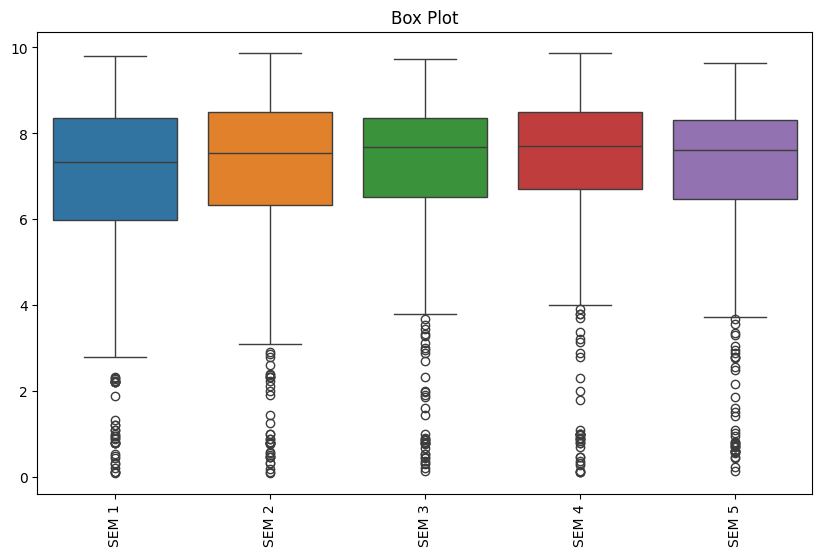

In [6]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df)
plt.xticks(rotation=90)
plt.title("Box Plot")
plt.show()

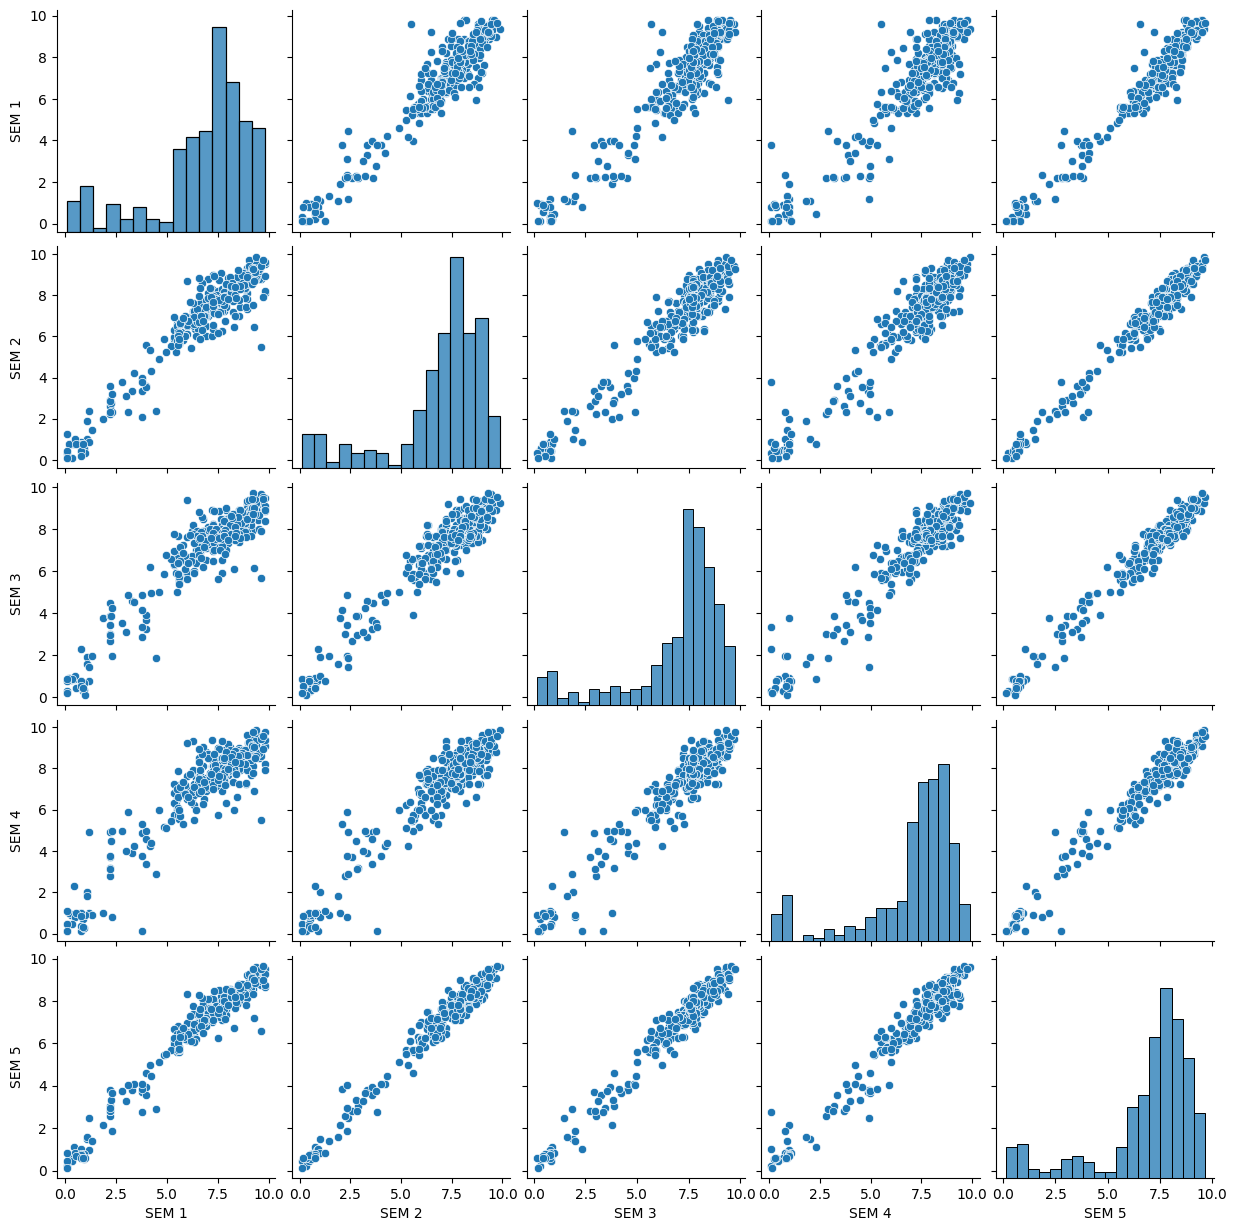

In [7]:
sns.pairplot(df)
plt.show()

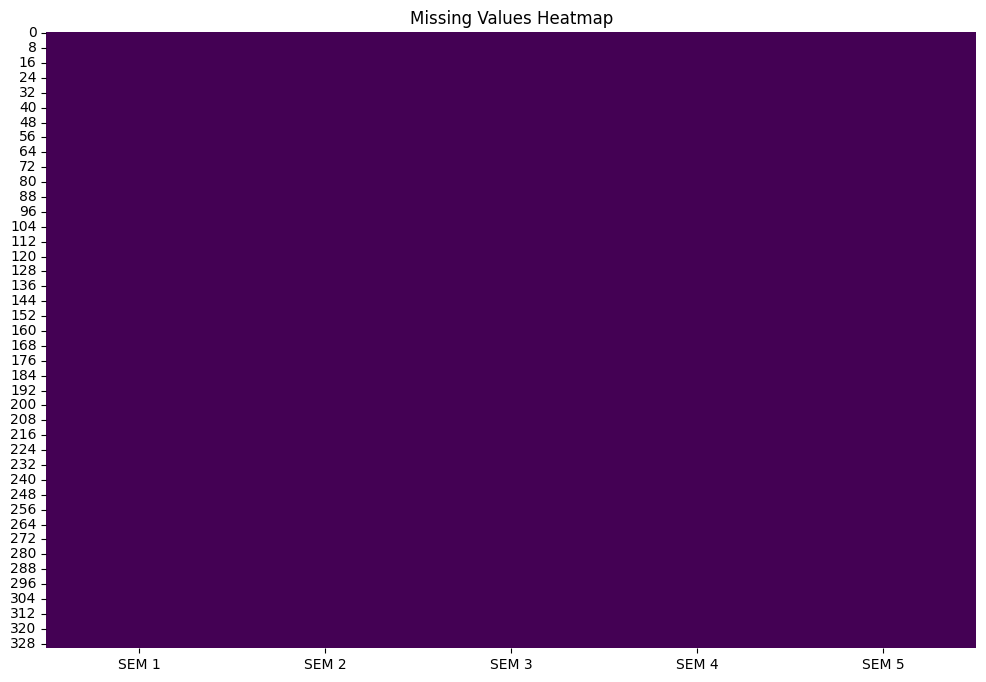

In [9]:
plt.figure(figsize=(12,8))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Values Heatmap")
plt.show()

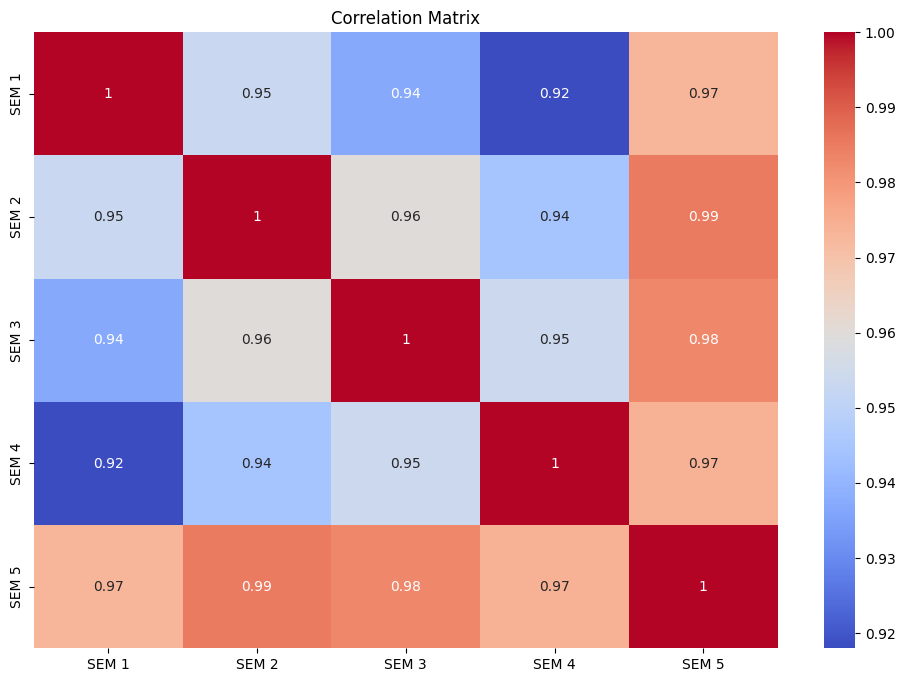

In [10]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Assuming you want to predict 'SEM 5' based on previous semester grades
X = df[['SEM 1', 'SEM 2', 'SEM 3', 'SEM 4']]
y = df['SEM 5']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

model = LinearRegression()

model.fit(X_train, y_train)

prediction = model.predict(X_test)

print("Intercept:", model.intercept_)
# For multiple features, coef_ will be an array, so print the whole array
print("Coefficients:", model.coef_)

print("MAE:", mean_absolute_error(y_test, prediction))
print("MSE:", mean_squared_error(y_test, prediction))
print("R2 Score:", r2_score(y_test, prediction))

Intercept: 0.0016321678815778284
Coefficients: [0.24982638 0.25019647 0.25002496 0.24991758]
MAE: 0.002598520559464134
MSE: 8.377509660473589e-06
R2 Score: 0.9999985284819518


In [16]:
X = df[['SEM 1','SEM 2','SEM 3','SEM 4']]
y = df['SEM 5']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

mlr = LinearRegression()

mlr.fit(X_train, y_train)

prediction = mlr.predict(X_test)

print("Intercept:", mlr.intercept_)
print("Coefficients:", mlr.coef_)

print("MAE:", mean_absolute_error(y_test, prediction))
print("MSE:", mean_squared_error(y_test, prediction))
print("R2 Score:", r2_score(y_test, prediction))

Intercept: 0.0016321678815778284
Coefficients: [0.24982638 0.25019647 0.25002496 0.24991758]
MAE: 0.002598520559464134
MSE: 8.377509660473589e-06
R2 Score: 0.9999985284819518
